In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [15]:
df = pd.read_csv("uber.csv/uber.csv")

print(df.head())
print(df.isnull().sum())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [17]:
df = df.dropna()

df = df.drop(['Unnamed: 0', 'key'], axis=1, errors='ignore')

df = df[(df['fare_amount'] > 0)]

print(df.head())

   fare_amount          pickup_datetime  pickup_longitude  pickup_latitude  \
0          7.5  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1          7.7  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2         12.9  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3          5.3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4         16.0  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         -73.965316         40.803349                3  
4         -73.973082         40.761247                5  


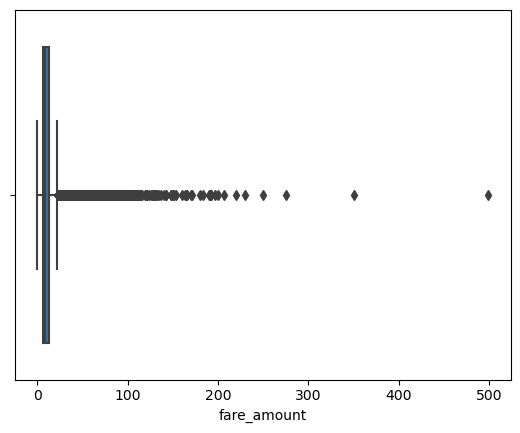

In [20]:
sns.boxplot(x=df['fare_amount'])
plt.show()

# Remove extreme fare outliers
df = df[df['fare_amount'] < df['fare_amount'].quantile(0.99)]

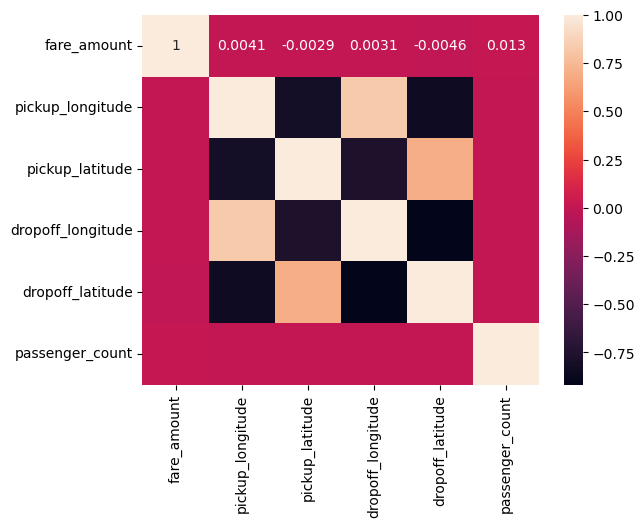

In [22]:
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

In [24]:
X = df[['pickup_longitude', 'pickup_latitude',
        'dropoff_longitude', 'dropoff_latitude',
        'passenger_count']]

y = df['fare_amount']

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [28]:
lr = LinearRegression()

lr.fit(X_train, y_train)

pred1 = lr.predict(X_test)

print("Linear Regression R2:", r2_score(y_test, pred1))
print("Linear Regression RMSE:", np.sqrt(mean_squared_error(y_test, pred1)))

Linear Regression R2: 0.0002868270748485058
Linear Regression RMSE: 8.048878839630015


In [30]:
rf = RandomForestRegressor(n_estimators=10, random_state=42)

rf.fit(X_train, y_train)

pred2 = rf.predict(X_test)

print("Random Forest R2:", r2_score(y_test, pred2))
print("Random Forest RMSE:", np.sqrt(mean_squared_error(y_test, pred2)))

Random Forest R2: 0.7732975936242336
Random Forest RMSE: 3.8328846341855622


In [31]:
print("Model Comparison")

print("Linear Regression R2:", r2_score(y_test, pred1))
print("Random Forest R2:", r2_score(y_test, pred2))

print("Linear Regression RMSE:",
      np.sqrt(mean_squared_error(y_test, pred1)))

print("Random Forest RMSE:",
      np.sqrt(mean_squared_error(y_test, pred2)))

Model Comparison
Linear Regression R2: 0.0002868270748485058
Random Forest R2: 0.7732975936242336
Linear Regression RMSE: 8.048878839630015
Random Forest RMSE: 3.8328846341855622
